<a href="https://colab.research.google.com/github/Agapenng/Nkaepe/blob/main/Patients.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd

# === Load the dataset ===
df = pd.read_csv("/boot/Technical chalenge/c44_sim_av_patient.csv")  # Update path if needed

# ===  Clean & Explore ===

# Map gender codes to labels
df["GENDER_LABEL"] = df["GENDER"].map({1: "Male", 2: "Female"})

# Replace placeholders in ETHNICITY
df["ETHNICITY_CLEAN"] = df["ETHNICITY"].replace({
    "Z": "Unknown", "X": "Unknown", "0": "Invalid", "8": "Invalid", "CP": "Invalid"
})

# Check for duplicates
print("Duplicate PATIENTIDs:", df["PATIENTID"].duplicated().sum())

# Missing values summary
print("\nMissing values per column:\n", df.isna().sum())

Duplicate PATIENTIDs: 0

Missing values per column:
 PATIENTID                         0
GENDER                            0
ETHNICITY                     12874
DEATHCAUSECODE_1A            113394
DEATHCAUSECODE_1B            128446
DEATHCAUSECODE_1C            135943
DEATHCAUSECODE_2             120670
DEATHCAUSECODE_UNDERLYING    113395
DEATHLOCATIONCODE            113388
VITALSTATUS                       1
VITALSTATUSDATE                   5
LINKNUMBER                        1
GENDER_LABEL                      0
ETHNICITY_CLEAN               12874
dtype: int64


/tmp/ipython-input-13-1328375140.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="GENDER_LABEL", data=df, palette="pastel")


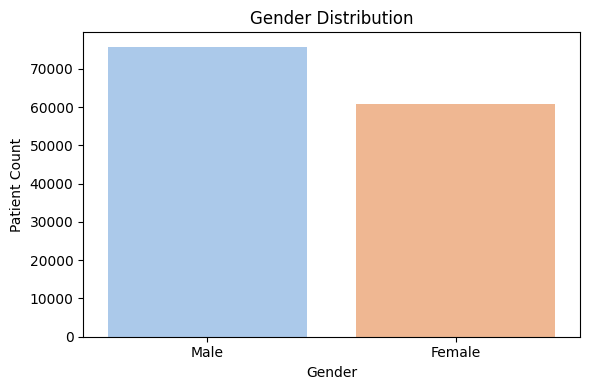

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

#  Gender Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x="GENDER_LABEL", data=df, palette="pastel")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Patient Count")
plt.tight_layout()
plt.show()

In [19]:
#===Gender & Ethnicity ===

# Gender distribution
gender_counts = df["GENDER_LABEL"].value_counts()
gender_percent = df["GENDER_LABEL"].value_counts(normalize=True) * 100
print("\nGender Distribution:\n", pd.DataFrame({"Count": gender_counts, "Percent": gender_percent.round(2)}))




Gender Distribution:
               Count  Percent
GENDER_LABEL                
Male          75720    55.43
Female        60873    44.57


In [20]:
# Ethnicity distribution (top 10)
ethnicity_counts = df["ETHNICITY_CLEAN"].value_counts().head(10)
ethnicity_percent = df["ETHNICITY_CLEAN"].value_counts(normalize=True).head(10) * 100
print("\nTop 10 Ethnicities:\n", pd.DataFrame({"Count": ethnicity_counts, "Percent": ethnicity_percent.round(2)}))




Top 10 Ethnicities:
                   Count  Percent
ETHNICITY_CLEAN                 
A                111594    90.20
Unknown            6283     5.08
C                  3294     2.66
B                  1316     1.06
S                   668     0.54
G                    93     0.08
L                    77     0.06
H                    70     0.06
N                    66     0.05
J                    57     0.05


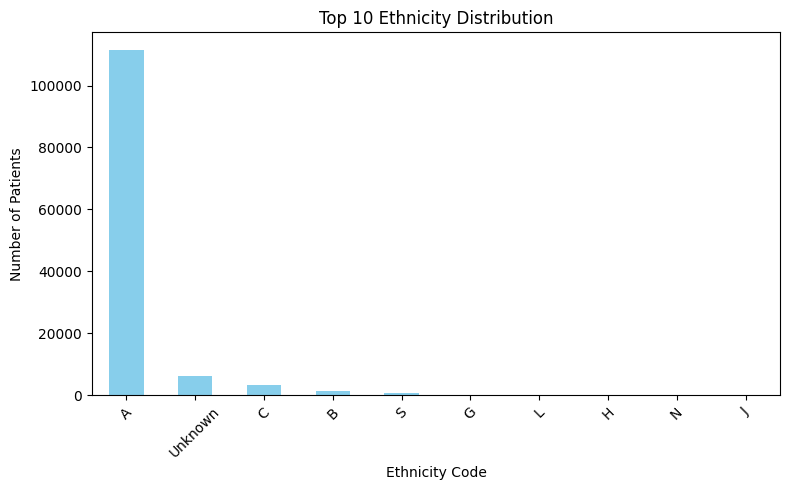

In [17]:
#  Ethnicity Distribution (Top 10)
plt.figure(figsize=(8, 5))
ethnicity_counts.plot(kind='bar', color='skyblue')
plt.title("Top 10 Ethnicity Distribution")
plt.xlabel("Ethnicity Code")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
# Gender vs Ethnicity cross-tab
print("\nGender vs Ethnicity (% within Gender):")
print(pd.crosstab(df["GENDER_LABEL"], df["ETHNICITY_CLEAN"], normalize='index').round(3).head())





Gender vs Ethnicity (% within Gender):
ETHNICITY_CLEAN      A      B      C    D    E    F      G      H  Invalid  \
GENDER_LABEL                                                                 
Female           0.904  0.010  0.028  0.0  0.0  0.0  0.001  0.001      0.0   
Male             0.901  0.011  0.026  0.0  0.0  0.0  0.001  0.000      0.0   

ETHNICITY_CLEAN      J    K      L    M      N    P    R      S  Unknown  
GENDER_LABEL                                                              
Female           0.001  0.0  0.001  0.0  0.001  0.0  0.0  0.005    0.049  
Male             0.000  0.0  0.001  0.0  0.000  0.0  0.0  0.006    0.052  


In [16]:
# ===  Vital Status ===

# Vital status counts
vital_counts = df["VITALSTATUS"].value_counts()
print("\nVital Status Counts:\n", vital_counts)

# Count of deceased and alive
alive = df[df["VITALSTATUS"] == "A"].shape[0]
deceased = df[df["VITALSTATUS"] == "D"].shape[0]
print("\nAlive:", alive)
print("Deceased:", deceased)
print("Deceased Percentage:", round(deceased / len(df) * 100, 2), "%")


Vital Status Counts:
 VITALSTATUS
A     112903
D      23451
X5       191
D5        34
X4         5
D4         4
X2         3
X          1
Name: count, dtype: int64

Alive: 112903
Deceased: 23451
Deceased Percentage: 17.17 %


In [21]:
# ===  Cause of Death ===

# Deceased subset
df_deceased = df[df["VITALSTATUS"] == "D"]

# Top underlying causes
print("\nTop 10 Underlying Causes of Death:")
print(df_deceased["DEATHCAUSECODE_UNDERLYING"].value_counts().head(10))




Top 10 Underlying Causes of Death:
DEATHCAUSECODE_UNDERLYING
U071    1346
F03     1280
I259    1118
C349     971
J189     746
I219     701
G309     664
C61      628
I64      592
F019     463
Name: count, dtype: int64


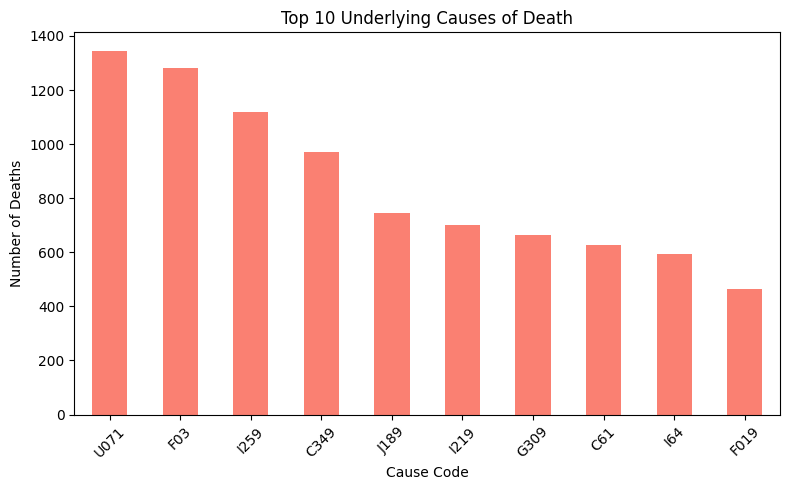

In [24]:
#  Underlying Cause of Death (Top 10)
top_causes = df_deceased["DEATHCAUSECODE_UNDERLYING"].value_counts().head(10)
plt.figure(figsize=(8, 5))
top_causes.plot(kind='bar', color='salmon')
plt.title("Top 10 Underlying Causes of Death")
plt.xlabel("Cause Code")
plt.ylabel("Number of Deaths")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
# Top death locations
print("\nTop 5 Death Locations:")
print(df_deceased["DEATHLOCATIONCODE"].value_counts().head(5))




Top 5 Death Locations:
DEATHLOCATIONCODE
1    10578
4     7344
X     2539
5     1146
6      873
Name: count, dtype: int64


In [23]:
# Count skin cancer-related deaths (C44 prefix)
death_cols = ['DEATHCAUSECODE_1A', 'DEATHCAUSECODE_1B', 'DEATHCAUSECODE_1C', 'DEATHCAUSECODE_2', 'DEATHCAUSECODE_UNDERLYING']
df_deceased["SKIN_CANCER_DEATH"] = df_deceased[death_cols].apply(
    lambda row: any(str(code).startswith("C44") for code in row if pd.notna(code)), axis=1
)
skin_cancer_deaths = df_deceased["SKIN_CANCER_DEATH"].sum()
print("\nSkin cancer-related deaths (C44):", skin_cancer_deaths)
print("Percentage of all deaths:", round(skin_cancer_deaths / deceased * 100, 2), "%")



Skin cancer-related deaths (C44): 704
Percentage of all deaths: 3.0 %


/tmp/ipython-input-23-2462397948.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_deceased["SKIN_CANCER_DEATH"] = df_deceased[death_cols].apply(
